# Program 03: catastrophic forgetting

**What:** train on task 0, then task 1, up to task 9, with no protection at all. After each task, test on *every* task seen so far and store the results in `acc[after_task][on_task]`.

**Why:** this is the problem continual learning exists to solve. You need to see it yourself.

**Understanding note:** the weights that solved task 0 get overwritten by gradients from task 1. Nothing in plain training protects old knowledge. Forgetting here is *accidental*; unlearning (Phase C on) is forgetting *on purpose*.

**Done when:** task 0 accuracy drops close to 0 after a few tasks, and you can read the accuracy matrix.

## 1. Setup
The training loop from program 01 now lives in `common/train.py`, so every later program reuses it.

In [1]:
import sys, time
from pathlib import Path

# Find the project root (the folder that holds common/), whether this notebook
# was opened from the project root or from programs/.
ROOT = Path.cwd() if (Path.cwd() / "common").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # lets us import common/

import matplotlib.pyplot as plt
import numpy as np
import torch

from common.data import N_TASKS, SplitCIFAR100, task_classes
from common.models import resnet18_cifar
from common.train import average_accuracy, evaluate_tasks, forgetting, new_acc_matrix, train_one_epoch
from common.utils import RESULTS_DIR, get_device, log_run, set_seed

SETTINGS = {"epochs": 5, "lr": 0.03, "batch_size": 32, "seed": 0, "workers": 2}
set_seed(SETTINGS["seed"])
device = get_device()
print("device:", device)

device: cuda


## 2. Data and model

One ResNet-18 with a **single 100-way output**. This is class-incremental learning: at test time the model must pick among all 100 classes and is never told the task id. The outputs for classes it hasn't met yet are still there; they just never got trained.

In [2]:
data = SplitCIFAR100(seed=SETTINGS["seed"], batch_size=SETTINGS["batch_size"], num_workers=SETTINGS["workers"])
model = resnet18_cifar(num_classes=100).to(device)
scaler = torch.amp.GradScaler(enabled=device.type == "cuda")
print("output size:", model.fc.out_features)

output size: 100


## 3. Train task by task, test on everything seen

Two accuracies per task:
- **class-IL**: best of all 100 outputs (our setting, hard).
- **task-IL**: only that task's 10 outputs may win (the task id is given, easier).

Each task gets a fresh plain SGD optimizer. Nothing remembers old tasks. About 1 minute per task on the laptop GPU.

In [3]:
acc_cil, acc_til = new_acc_matrix(), new_acc_matrix()
start = time.time()
for task in range(N_TASKS):
    train_loader, _ = data.get_task_loaders(task)
    optimizer = torch.optim.SGD(model.parameters(), lr=SETTINGS["lr"], momentum=0.9)
    for epoch in range(SETTINGS["epochs"]):
        loss, train_acc = train_one_epoch(model, train_loader, optimizer, scaler, device)

    cil, til = evaluate_tasks(model, data, task, device)
    acc_cil[task, : task + 1] = cil
    acc_til[task, : task + 1] = til
    print(f"task {task}: train acc {train_acc*100:5.1f}%  ({time.time()-start:.0f}s)   "
          "class-IL on seen tasks: " + " ".join(f"{a*100:5.1f}" for a in cil))

task 0: train acc  50.7%  (39s)   class-IL on seen tasks:  55.1
task 1: train acc  59.2%  (80s)   class-IL on seen tasks:   0.0  58.4
task 2: train acc  65.3%  (125s)   class-IL on seen tasks:   0.0   0.0  67.5
task 3: train acc  55.8%  (176s)   class-IL on seen tasks:   0.0   0.0   0.0  57.5
task 4: train acc  55.4%  (231s)   class-IL on seen tasks:   0.0   0.0   0.0   0.0  59.0
task 5: train acc  60.4%  (277s)   class-IL on seen tasks:   0.0   0.0   0.0   0.0   0.0  62.5
task 6: train acc  62.5%  (327s)   class-IL on seen tasks:   0.0   0.0   0.0   0.0   0.0   0.0  62.6
task 7: train acc  73.7%  (381s)   class-IL on seen tasks:   0.0   0.0   0.0   0.0   0.0   0.0   0.0  74.0
task 8: train acc  72.7%  (438s)   class-IL on seen tasks:   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  68.3
task 9: train acc  75.1%  (500s)   class-IL on seen tasks:   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  74.0


## 4. Read the accuracy matrix

Row *i* = after training task *i*. Column *j* = tested on task *j*. The diagonal is "just learned it"; everything left of the diagonal is "how much is left of an old task".

In [4]:
def show(acc, title):
    print(f"{title} (%)")
    print("      " + "".join(f"{t:>6}" for t in range(N_TASKS)) + "   avg")
    for i in range(N_TASKS):
        cells = "".join("     ." if np.isnan(v) else f"{v*100:6.1f}" for v in acc[i])
        print(f"after {i}{cells}  {average_accuracy(acc, i)*100:5.1f}")
    print()

show(acc_cil, "class-IL")
show(acc_til, "task-IL")
print(f"task 0: {acc_cil[0,0]*100:.1f}% right after learning it, {acc_cil[2,0]*100:.1f}% two tasks later, {acc_cil[-1,0]*100:.1f}% at the end")
print(f"average forgetting: class-IL {forgetting(acc_cil)*100:.1f} points, task-IL {forgetting(acc_til)*100:.1f} points")

class-IL (%)
           0     1     2     3     4     5     6     7     8     9   avg
after 0  55.1     .     .     .     .     .     .     .     .     .   55.1
after 1   0.0  58.4     .     .     .     .     .     .     .     .   29.2
after 2   0.0   0.0  67.5     .     .     .     .     .     .     .   22.5
after 3   0.0   0.0   0.0  57.5     .     .     .     .     .     .   14.4
after 4   0.0   0.0   0.0   0.0  59.0     .     .     .     .     .   11.8
after 5   0.0   0.0   0.0   0.0   0.0  62.5     .     .     .     .   10.4
after 6   0.0   0.0   0.0   0.0   0.0   0.0  62.6     .     .     .    8.9
after 7   0.0   0.0   0.0   0.0   0.0   0.0   0.0  74.0     .     .    9.2
after 8   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  68.3     .    7.6
after 9   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  74.0    7.4

task-IL (%)
           0     1     2     3     4     5     6     7     8     9   avg
after 0  55.1     .     .     .     .     .     .     .     .     .   55.1
aft

## 5. Plot
Left: one line per task. Middle: the matrix. Right: average accuracy, class-IL vs task-IL.

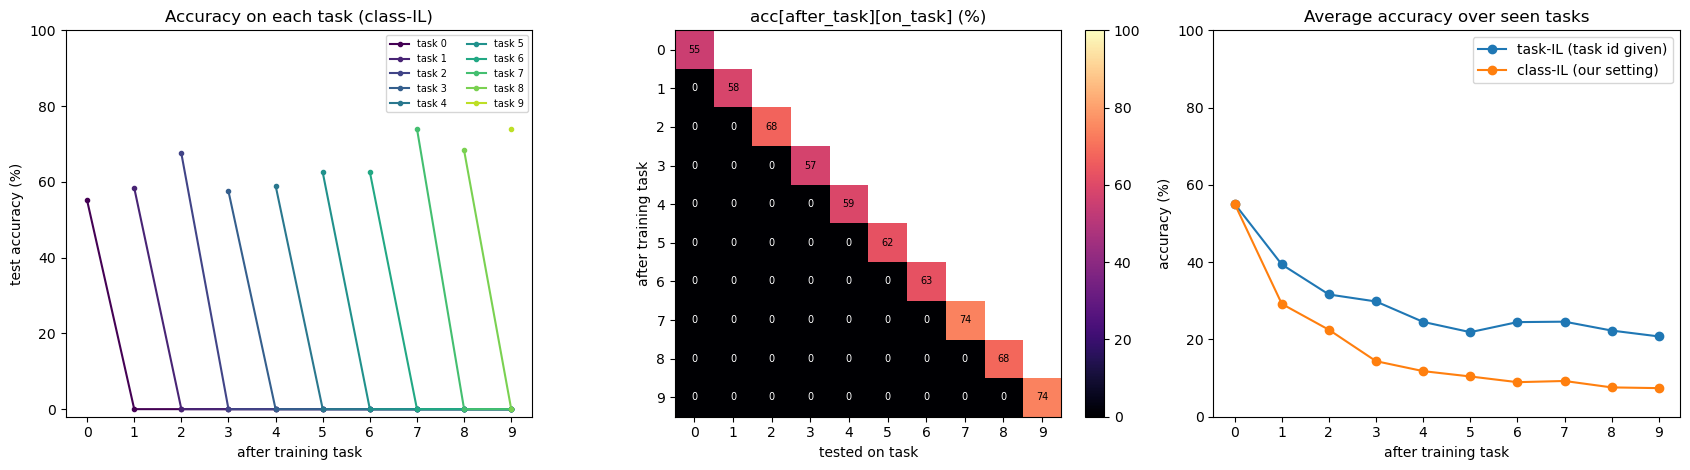

In [5]:
x = np.arange(N_TASKS)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
colors = plt.cm.viridis(np.linspace(0, 0.9, N_TASKS))
for t in range(N_TASKS):
    axes[0].plot(x[t:], acc_cil[t:, t] * 100, marker="o", ms=3, color=colors[t], label=f"task {t}")
axes[0].set(title="Accuracy on each task (class-IL)", xlabel="after training task", ylabel="test accuracy (%)", ylim=(-2, 100), xticks=x)
axes[0].legend(fontsize=7, ncol=2)

im = axes[1].imshow(acc_cil * 100, vmin=0, vmax=100, cmap="magma")
for i in range(N_TASKS):
    for j in range(i + 1):
        v = acc_cil[i, j] * 100
        axes[1].text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="black" if v > 50 else "white")
axes[1].set(title="acc[after_task][on_task] (%)", xlabel="tested on task", ylabel="after training task", xticks=x, yticks=x)
fig.colorbar(im, ax=axes[1], fraction=0.046)

axes[2].plot(x, [average_accuracy(acc_til, i) * 100 for i in x], marker="o", label="task-IL (task id given)")
axes[2].plot(x, [average_accuracy(acc_cil, i) * 100 for i in x], marker="o", label="class-IL (our setting)")
axes[2].set(title="Average accuracy over seen tasks", xlabel="after training task", ylabel="accuracy (%)", ylim=(0, 100), xticks=x)
axes[2].legend()
fig.tight_layout()
plt.show()

## 6. Why does class-IL collapse so completely?

Look at *what the model predicts* for task 0 test images at the end. If forgetting were "fuzzy", predictions would spread over task 0's classes. Instead they land almost entirely on the **last task's** classes: the newest output units have the largest weights and win every time.

In [6]:
_, test0 = data.get_task_loaders(0)
model.eval()
with torch.no_grad():
    preds = torch.cat([model(x.to(device)).argmax(1).cpu() for x, _ in test0])
pred_task = (preds // 10).bincount(minlength=N_TASKS)
for t in range(N_TASKS):
    print(f"predicted a task-{t} class: {pred_task[t].item()/len(preds)*100:5.1f}%")

# Size of each task's output weights: newer tasks have bigger ones.
w = model.fc.weight.detach().norm(dim=1).cpu().view(N_TASKS, 10).mean(1)
print("\naverage output-weight norm per task:", " ".join(f"{v:.2f}" for v in w))

predicted a task-0 class:   0.0%
predicted a task-1 class:   0.0%
predicted a task-2 class:   0.0%
predicted a task-3 class:   0.0%
predicted a task-4 class:   0.0%
predicted a task-5 class:   0.0%
predicted a task-6 class:   0.0%
predicted a task-7 class:   0.0%
predicted a task-8 class:   0.0%
predicted a task-9 class: 100.0%

average output-weight norm per task: 1.57 1.87 2.08 1.99 2.04 2.01 2.09 2.08 2.12 2.64


## 7. Log the run

In [7]:
to_json = lambda a: [[None if np.isnan(v) else round(float(v), 4) for v in r] for r in a]
log_run("03_naive_sequential", SETTINGS,
        {"acc_class_il": to_json(acc_cil), "acc_task_il": to_json(acc_til),
         "final_avg_class_il": average_accuracy(acc_cil, N_TASKS - 1),
         "final_avg_task_il": average_accuracy(acc_til, N_TASKS - 1),
         "forgetting_class_il": forgetting(acc_cil), "forgetting_task_il": forgetting(acc_til)})
np.savez(RESULTS_DIR / "03_acc_matrix.npz", class_il=acc_cil, task_il=acc_til)
print("logged to", RESULTS_DIR / "runs.jsonl")

logged to /run/media/adarsh/AAE039EFE039C1FD/std/research/results/runs.jsonl


## Lab notebook

*Write one paragraph here: what you saw, and what surprised you.*

Questions to answer in it:
1. After which task does task 0 first fall below 5% (class-IL)?
2. Task-IL keeps much more. What does that say about whether the *features* for task 0 are really gone, versus the output layer just preferring new classes? (This matters a lot in program 14.)
3. Forgetting here is accidental. How is that different from the forgetting we will *ask* for in Phase C?